# Exploratory Analysis on Modeshapes

# Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
import os
parent_dir = os.path.abspath("../../libraries/surrogate_modelling")
sys.path.insert(0, parent_dir)

from preprocess_modeshape_data import *
from plotting_functions import *
import pandas as pd
import numpy as np

/home/vemese/miniforge3/envs/Buildchain_sandbox/lib/python3.10/site-packages/shap/plots/colors/_colorconv.py:819: DeprecationWarning: Converting `np.inexact` or `np.floating` to a dtype is deprecated. The current result is `float64` which is not strictly correct.
  if np.issubdtype(dtype_in, np.dtype(dtype).type):
<frozen importlib._bootstrap>:241: RuntimeWarning: numpy.ufunc size changed, may indicate binary incompatibility. Expected 216 from C header, got 232 from PyObject


# Load data

In [2]:
df_modeshapes = df_from_unv('../data/OMA hospital/hospital_data_06_01.unv')
weather_df = preprocess_weather_data('../data/OMA hospital/granada_weather_data.csv')

In [3]:
merged_df = merge_dataframes(df_modeshapes, weather_df)
merged_df['mode_id'].value_counts()

mode_id
 3    1802
 1    1799
 2    1279
-1    1255
 0     356
 6     350
-2     169
Name: count, dtype: int64

Mode ids -1 and -2 correspond to unrecognised or duplicate modes.

In [4]:
modeshapes_dict = separate__and_flip_modes(merged_df)
modeshapes_df = merge_modes(modeshapes_dict)
modeshapes_df.head(2)

,phi_sensor_1_real,phi_sensor_1_imag,phi_sensor_2_real,phi_sensor_2_imag,phi_sensor_3_real,phi_sensor_3_imag,phi_sensor_4_real,phi_sensor_4_imag,phi_sensor_5_real,phi_sensor_5_imag,...,frequency,xi,Datetime,Temperature,Humidity,Dew Point,Apparent Temperature,Wind Speed,Wind Direction,mode_id
0,0.010114,0.029889,0.53301,-0.036790,0.090962,-0.015602,-0.063927,0.027691,1.0,0.0,...,3.62425,0.046678,2025-02-04 19:33:49,5.5,74.0,1.3,3.4,1.5,150.0,0
1,0.067700,0.073652,0.57011,-0.038071,0.069899,0.048334,0.000928,0.193863,1.0,0.0,...,3.61993,0.059198,2025-02-05 00:38:51,1.5,87.0,-0.4,-1.2,3.5,118.0,0


# Frequencies

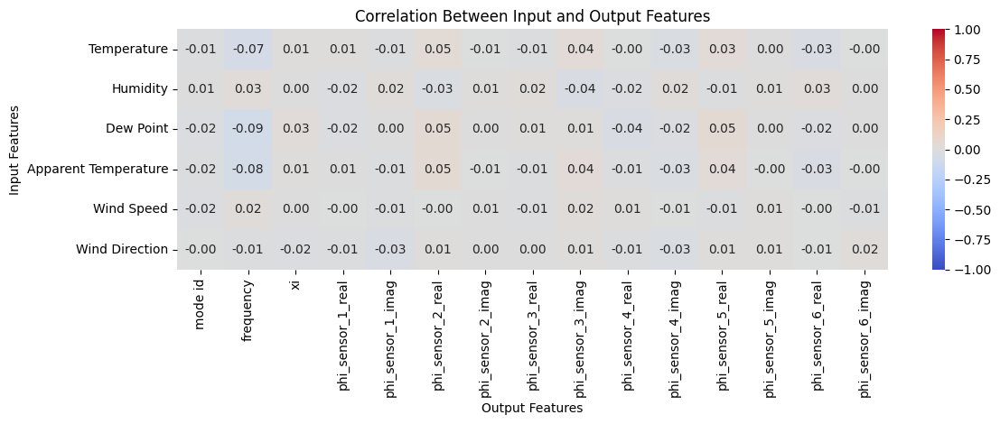

In [5]:
fig = plot_correlation(weather_df, df_modeshapes, mode='input-output')

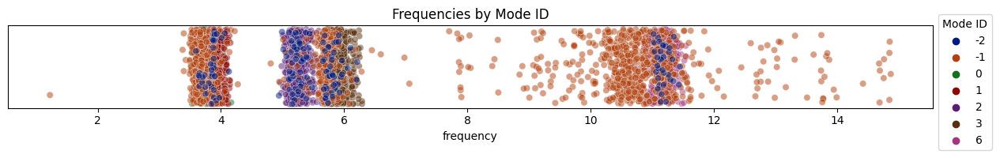

In [6]:
y_jitter = np.random.uniform(-0.1, 0.1, size=len(modeshapes_df))

plt.figure(figsize=(12, 2))
sns.scatterplot(x='frequency', y=y_jitter, hue='mode_id', data=modeshapes_df, palette='dark', alpha=0.5)
plt.yticks([])
plt.xlabel('frequency')
plt.title('Frequencies by Mode ID')
plt.tight_layout()
plt.legend(title='Mode ID', bbox_to_anchor=(1, 1.2))
plt.show()

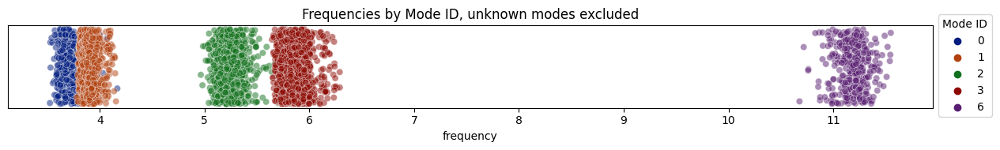

In [7]:
data = modeshapes_df[~modeshapes_df['mode_id'].isin([-1, -2])].copy()

y_jitter = np.random.uniform(-0.1, 0.1, size=len(data))

plt.figure(figsize=(12, 2))
sns.scatterplot(x='frequency', y=y_jitter, hue='mode_id', data=data, palette='dark', alpha=0.5)
plt.yticks([])
plt.xlabel('frequency')
plt.title('Frequencies by Mode ID, unknown modes excluded')
plt.tight_layout()
plt.legend(title='Mode ID', bbox_to_anchor=(1, 1.2))
plt.show()

In [8]:
# Sort the mode_id categories
sorted_modes = sorted(modeshapes_df['mode_id'].unique())
mode_id_mapping = {mode: i for i, mode in enumerate(sorted_modes)}

# Apply mapping and add jitter
modeshapes_df['jitter'] = modeshapes_df['mode_id'].map(mode_id_mapping) + np.random.normal(scale=0.1, size=len(modeshapes_df))

# Create plot
fig = px.scatter(modeshapes_df, x='jitter', y='frequency', width=1500, height=400)
fig.update_traces(marker=dict(color='royalblue'))

# Update layout with title and x-axis labels
fig.update_layout(
    title=dict(
        text='Frequencies by Mode ID with Jitter',
        x=0.5,
        xanchor='center',
        font=dict(size=18)
    ),
    xaxis=dict(
        tickmode='array',
        tickvals=list(mode_id_mapping.values()),
        ticktext=list(mode_id_mapping.keys()),
        title='Mode ID'
    ),
    yaxis=dict(title='Frequency')
)

fig.show()

/home/vemese/miniforge3/envs/Buildchain_sandbox/lib/python3.10/site-packages/plotly/io/_renderers.py:395: DeprecationWarning:

distutils Version classes are deprecated. Use packaging.version instead.



In [9]:
fig = scatter_plot_modes_subplots(modeshapes_dict, x_key='Temperature', y_key='frequency', modes=[0, 1, 2, 3, 6])
fig.show()

In [10]:
fig = scatter_plot_modes_subplots(modeshapes_dict, x_key='Humidity', y_key='frequency', modes=[0, 1, 2, 3, 6])
fig.show()

# Mode 1 plots

In [11]:
mode = 1

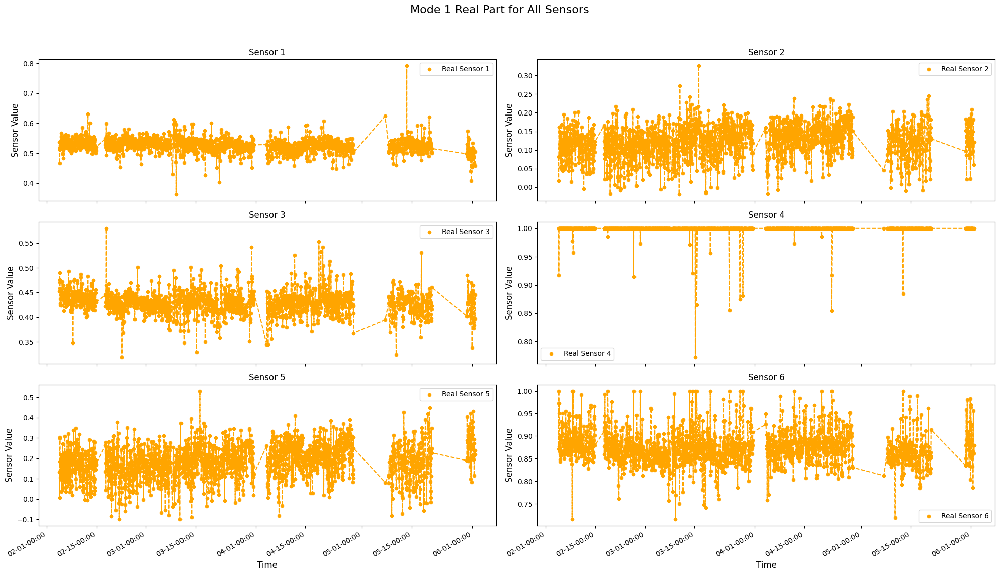

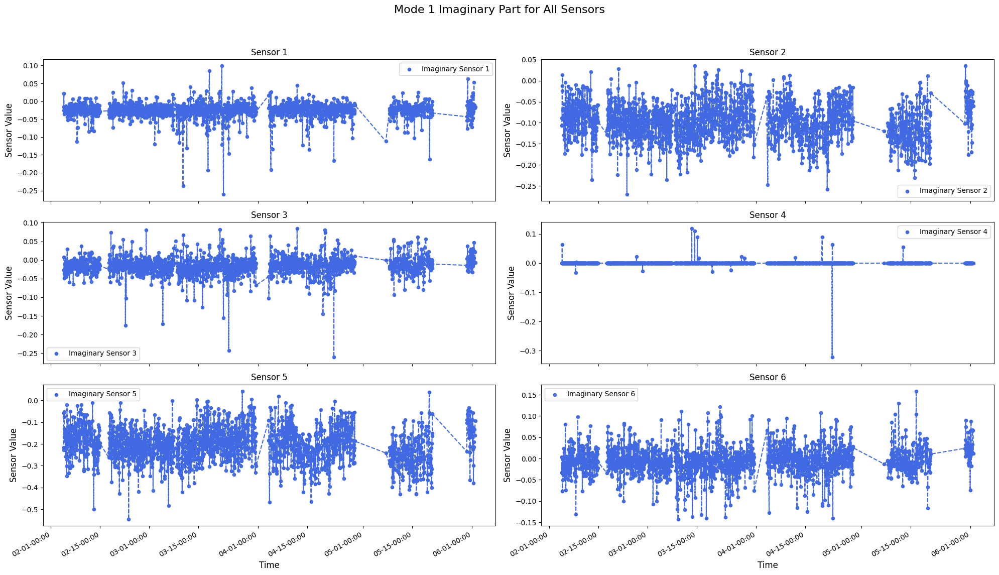

In [12]:
fig_real, fig_imag = plot_parts(modeshapes_dict, mode)

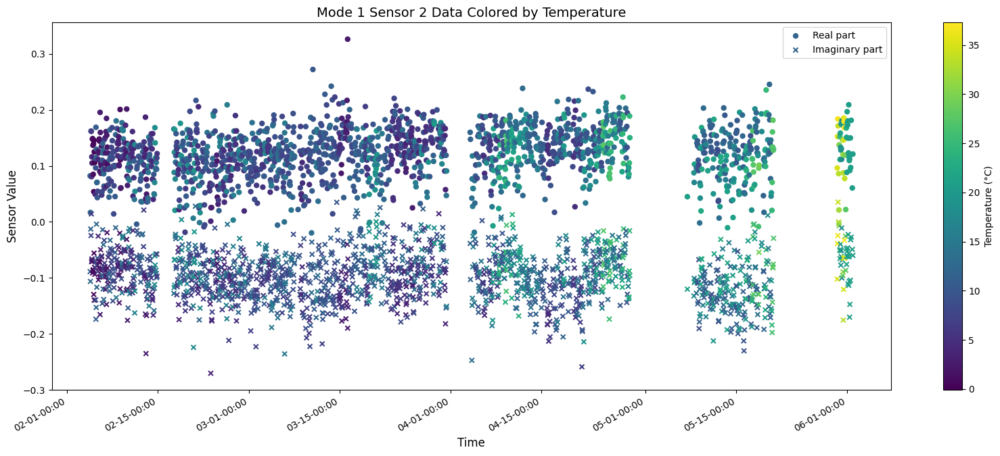

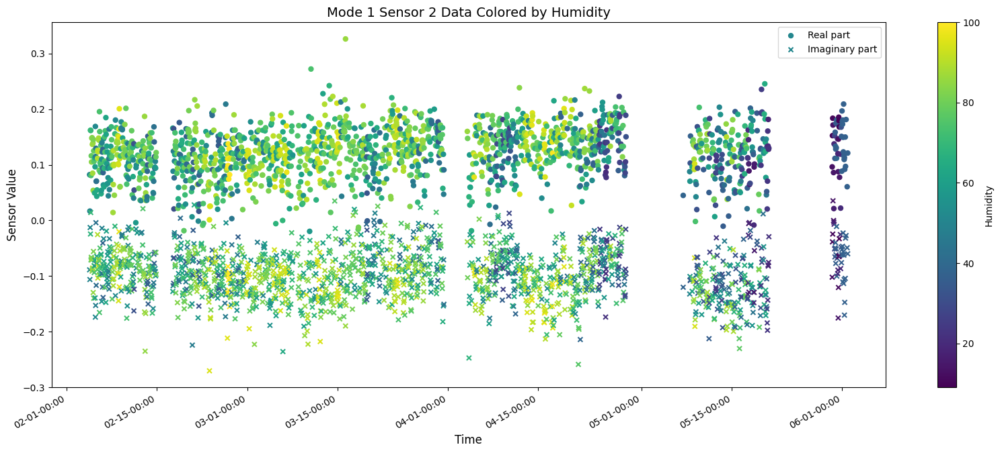

In [13]:
fig_temp = plot_sensor_complex_colored(modeshapes_dict, mode, sensor=2, color_by='Temperature')
fig_hum = plot_sensor_complex_colored(modeshapes_dict, mode, sensor=2, color_by='Humidity')

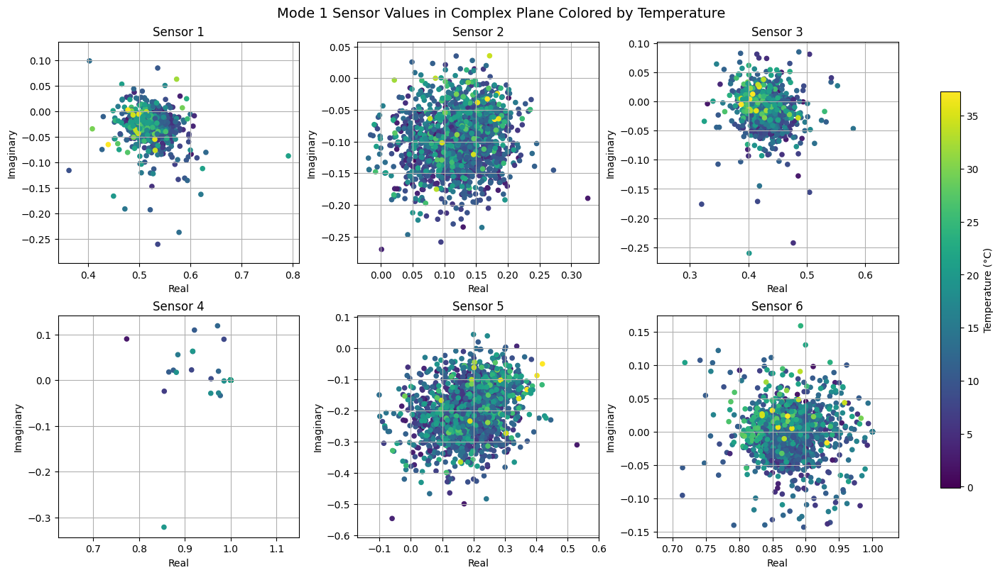

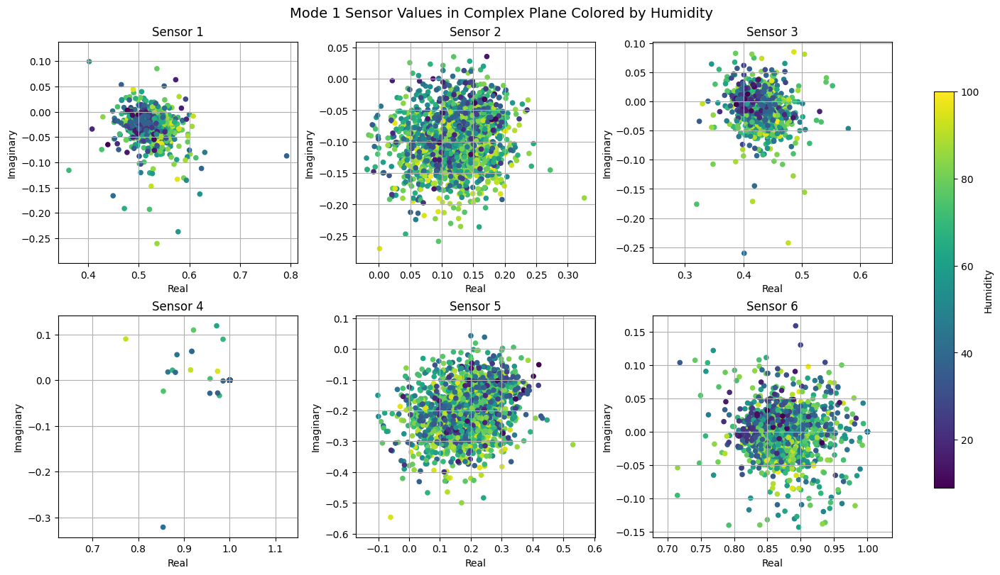

In [14]:
fig_temp = plot_complex_plane_all_sensors(modeshapes_dict, mode, color_by='Temperature')
fig_hum = plot_complex_plane_all_sensors(modeshapes_dict, mode, color_by='Humidity')

In [15]:
fig = plot_mode_shapes_3d(modeshapes_dict, mode, color_by='Temperature')
fig.show()

In [16]:
fig = plot_mode_shapes_3d(modeshapes_dict, mode, color_by='Humidity')
fig.show()